- ชื่อ-นามสกุล: **นายปพนพัชร์ มีวน**
- รหัสนักศึกษา: **6709650458**

# Assignment: NYC Taxi — Data Lifecycle & Pipeline (Submission 1 - Data Lifecycle Baseline)

**โจทย์คือ:** ใช้ข้อมูล NYC Taxi เพื่อตอบคำถาม Which taxi type was the most used in the first half of 2024?

Notebook นี้วิเคราะห์ข้อมูลการเดินทางของ NYC TLC ตั้งแต่เดือนมกราคมถึงมิถุนายนปี 2024 โดยเปรียบเทียบรถที่ให้บริการ 4 ประเภท ได้แก่ Yellow Taxi, Green Taxi, For-Hire Vehicle (FHV) และ High Volume FHV (FHVHV)

## 1. กำหนดความหมายของ “most used”
ซึ่งคำว่า **most used** อาจหมายถึง จำนวนเที่ยว, จำนวนผู้โดยสาร, ระยะทาง หรือค่าโดยสารก็ได้

ในงานนี้ผมกำหนดว่า: **most used** หมายถึง จำนวนเที่ยวของรถ เพราะสื่อถึงการใช้งานที่ตรงประเด็นที่สุด

>**ฉะนั้น Most used = ประเภทบริการที่มีจำนวน valid trip records มากที่สุดในช่วง 1 มกราคม–30 มิถุนายน 2024**

หมายความว่าหนึ่งแถวใน Trip Record ถูกใช้แทนหนึ่งเที่ยว ส่วนคำว่า **valid** ในงานนี้จะกำหนดความหมายให้หมายถึงแถวที่:

1. มีเวลา Pickup และ Dropoff
2. เวลา Dropoff ไม่ก่อนเวลา Pickup
3. เวลา Pickup อยู่ในเดือนที่ระบุไว้ในชื่อ file

และนอกจากเลือกจำนวนเที่ยวเป็นตัวชี้วัดเพราะมีความหมายตรงกับคำว่า “ถูกใช้” อีกเหตุผลคือ สามารถใช้เปรียบเทียบได้กับข้อมูลรถทั้ง 4 ประเภท ขณะที่จำนวนผู้โดยสาร ระยะทาง และค่าโดยสารมี column หรือวิธีบันทึกไม่เหมือนกันทุกประเภท

## 2. ข้อมูลและแหล่งข้อมูล

**แหล่งข้อมูลมาจาก:** [NYC Taxi & Limousine Commission (TLC) — Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)

ข้อมูลที่ใช้เป็นไฟล์ Parquet รายเดือนจาก website TLC จำนวน **24 ไฟล์** คือมาจาก
- 4 ประเภทบริการ: Yellow, Green, FHV และ FHVHV
- 6 เดือน: มกราคม–มิถุนายน 2024

TLC อธิบายคร่าวๆว่าข้อมูล Yellow/Green มาจากผู้ให้บริการเทคโนโลยี ส่วน FHV มาจากรายงานของฐานรถ และ TLC จะไม่รับประกันความถูกต้องหรือความครบถ้วนทั้งหมด จึงต้องตรวจคุณภาพข้อมูลก่อนสรุปผล

โดย Notebook อ่าน Parquet จาก URL โดยตรง และเก็บเฉพาะตารางผลลัพธ์ขนาดเล็กหลังตรวจสอบแล้วไว้เป็น CSV ใน runtime

## 3. Data Lifecycle ที่ใช้คือ

1. **Acquire** - ระบุ URL ของไฟล์ Parquet 24 ไฟล์จาก TLC
2. **Store** - ไฟล์ข้อมูลดิบอยู่ที่ TLC และไม่ถูกแก้ไข
3. **Ingest** - ใช้ DuckDB อ่านเฉพาะ columnเวลาที่จำเป็นจาก Parquet
4. **Inspect** - ตรวจจำนวนคอลัมน์ Schema ตัวอย่างข้อมูล และดูปัญหาคุณภาพ
5. **Clean** - ใช้เกณฑ์ Valid Trip เดียวกันกับรถทุกประเภท
6. **Transform & Integrate** - ทำชื่อ column Pickup/Dropoff ให้มีความหมายเดียวกัน และรวมผลรายเดือนให้เป็นตารางมาตรฐาน
7. **Analyze** - รวมจำนวนเที่ยว 6 เดือนและเปรียบเทียบระหว่างประเภท
8. **Present** - แสดงตาราง กราฟ คำตอบ และข้อจำกัด

## 4. เตรียมเครื่องมือที่ใช้

ใช้ DuckDB อ่านและคำนวณบน Parquet จาก Storage โดยตรง เพื่อลดการใช้ RAM จากนั้นใช้ Pandas จัดตารางสรุป และใช้ Matplotlib สร้างกราฟ

In [ ]:
# ติดตั้ง DuckDB สำหรับ Colab
%pip -q install duckdb

In [ ]:
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# แสดงตัวเลขจำนวนมากให้อ่านง่ายขึ้น
pd.options.display.float_format = "{:,.2f}".format

# สร้าง connection ใน memory ไม่แก้ไขไฟล์ต้นฉบับ
con = duckdb.connect()

print("DuckDB version:", duckdb.__version__)
print("Pandas version:", pd.__version__)

DuckDB version: 1.3.2
Pandas version: 2.2.3


## 5. สร้างรายการไฟล์ที่ต้องใช้

แต่ละประเภทใช้ชื่อคอลัมน์เวลาไม่เหมือนกัน จึงเก็บชื่อคอลัมน์ไว้ใน `taxi_info` เพื่อใช้เกณฑ์เดียวกันภายหลัง ตัวอย่างเช่น Yellow ใช้ `tpep_pickup_datetime` แต่ FHV/FHVHV ใช้ `pickup_datetime`

In [ ]:
# ข้อมูลพื้นฐานของแต่ละประเภทและชื่อ column เวลาจริงใน file
taxi_info = {
    "yellow": {
        "name": "Yellow Taxi",
        "pickup": "tpep_pickup_datetime",
        "dropoff": "tpep_dropoff_datetime",
    },
    "green": {
        "name": "Green Taxi",
        "pickup": "lpep_pickup_datetime",
        "dropoff": "lpep_dropoff_datetime",
    },
    "fhv": {
        "name": "For-Hire Vehicle (FHV)",
        "pickup": "pickup_datetime",
        "dropoff": "dropOff_datetime",
    },
    "fhvhv": {
        "name": "High Volume FHV (FHVHV)",
        "pickup": "pickup_datetime",
        "dropoff": "dropoff_datetime",
    },
}

base_url = "https://d37ci6vzurychx.cloudfront.net/trip-data"
files = []

# สร้างรายการ 4 ประเภท x 6 เดือน = 24 ไฟล์
for taxi_type, info in taxi_info.items():
    for month_number in range(1, 7):
        month = f"2024-{month_number:02d}"
        month_start = f"2024-{month_number:02d}-01"
        month_end = "2024-07-01" if month_number == 6 else f"2024-{month_number + 1:02d}-01"

        files.append({
            "taxi_type": taxi_type,
            "taxi_name": info["name"],
            "month": month,
            "month_start": month_start,
            "month_end": month_end,
            "pickup_column": info["pickup"],
            "dropoff_column": info["dropoff"],
            "url": f"{base_url}/{taxi_type}_tripdata_{month}.parquet",
        })

file_list = pd.DataFrame(files)

print(f"Number of source files: {len(file_list)}")
display(file_list[["taxi_type", "month", "pickup_column", "dropoff_column"]])

Number of source files: 24


,taxi_type,month,pickup_column,dropoff_column
0,yellow,2024-01,tpep_pickup_datetime,tpep_dropoff_datetime
1,yellow,2024-02,tpep_pickup_datetime,tpep_dropoff_datetime
2,yellow,2024-03,tpep_pickup_datetime,tpep_dropoff_datetime
3,yellow,2024-04,tpep_pickup_datetime,tpep_dropoff_datetime
4,yellow,2024-05,tpep_pickup_datetime,tpep_dropoff_datetime
5,yellow,2024-06,tpep_pickup_datetime,tpep_dropoff_datetime
6,green,2024-01,lpep_pickup_datetime,lpep_dropoff_datetime
7,green,2024-02,lpep_pickup_datetime,lpep_dropoff_datetime
8,green,2024-03,lpep_pickup_datetime,lpep_dropoff_datetime
9,green,2024-04,lpep_pickup_datetime,lpep_dropoff_datetime


## 6. ตรวจดู Schema ของข้อมูลแต่ละประเภท

ก่อนที่จะรวมข้อมูล ต้องตรวจว่าแต่ละชุดมีโครงสร้างอย่างไร ในที่นี้ใช้เดือนมกราคมเป็นตัวอย่างของแต่ละประเภท และนับจำนวนคอลัมน์พร้อมแสดงคอลัมน์ชนิดเวลา

In [ ]:
schema_rows = []

# อ่าน Schema จากไฟล์เดือนมกราคมของแต่ละประเภท
for taxi_type, info in taxi_info.items():
    january_url = (
        f"{base_url}/{taxi_type}_tripdata_2024-01.parquet"
    )

    # DESCRIBE อ่านชื่อคอลัมน์และชนิดข้อมูล
    # โดยไม่โหลดข้อมูลทุกแถวเข้ามาเป็น Pandas DataFrame
    schema = con.execute(
        "DESCRIBE SELECT * FROM read_parquet(?)",
        [january_url],
    ).fetchdf()

    # เพิ่มประเภท taxi เพื่อให้รู้ว่า Schema มาจากไฟล์ประเภทใด
    schema["taxi_type"] = taxi_type

    # เก็บผลไว้ใน list ก่อนนำมารวมกัน
    schema_rows.append(schema)


# รวม Schema ของทั้ง 4 ประเภทไว้ใน DataFrame เดียว
all_schemas = pd.concat(
    schema_rows,
    ignore_index=True,
)


# สรุปจำนวนคอลัมน์และรายชื่อคอลัมน์เวลา
schema_summary = (
    all_schemas
    .groupby("taxi_type", as_index=False)
    .agg(
        number_of_columns=(
            "column_name",
            "count",
        ),
        datetime_columns=(
            "column_name",
            lambda values: ", ".join(
                values[
                    all_schemas.loc[
                        values.index,
                        "column_type",
                    ] == "TIMESTAMP"
                ]
            ),
        ),
    )
)

print("Schema summary")
display(schema_summary)


# แสดง Schema แบบละเอียดแยกตามประเภทรถ
# เพื่อให้ตรวจสอบความแตกต่างของชื่อคอลัมน์ได้โดยตรง
for taxi_type, info in taxi_info.items():
    print(f"\nSchema: {info['name']}")

    selected_schema = all_schemas[
        all_schemas["taxi_type"] == taxi_type
    ][
        ["column_name", "column_type"]
    ].reset_index(drop=True)

    display(selected_schema)

Schema summary


,taxi_type,number_of_columns,datetime_columns
0,fhv,7,"pickup_datetime, dropOff_datetime"
1,fhvhv,24,"request_datetime, on_scene_datetime, pickup_da..."
2,green,20,"lpep_pickup_datetime, lpep_dropoff_datetime"
3,yellow,19,"tpep_pickup_datetime, tpep_dropoff_datetime"



Schema: Yellow Taxi


,column_name,column_type
0,VendorID,INTEGER
1,tpep_pickup_datetime,TIMESTAMP
2,tpep_dropoff_datetime,TIMESTAMP
3,passenger_count,BIGINT
4,trip_distance,DOUBLE
5,RatecodeID,BIGINT
6,store_and_fwd_flag,VARCHAR
7,PULocationID,INTEGER
8,DOLocationID,INTEGER
9,payment_type,BIGINT



Schema: Green Taxi


,column_name,column_type
0,VendorID,INTEGER
1,lpep_pickup_datetime,TIMESTAMP
2,lpep_dropoff_datetime,TIMESTAMP
3,store_and_fwd_flag,VARCHAR
4,RatecodeID,BIGINT
5,PULocationID,INTEGER
6,DOLocationID,INTEGER
7,passenger_count,BIGINT
8,trip_distance,DOUBLE
9,fare_amount,DOUBLE



Schema: For-Hire Vehicle (FHV)


,column_name,column_type
0,dispatching_base_num,VARCHAR
1,pickup_datetime,TIMESTAMP
2,dropOff_datetime,TIMESTAMP
3,PUlocationID,BIGINT
4,DOlocationID,BIGINT
5,SR_Flag,BIGINT
6,Affiliated_base_number,VARCHAR



Schema: High Volume FHV (FHVHV)


,column_name,column_type
0,hvfhs_license_num,VARCHAR
1,dispatching_base_num,VARCHAR
2,originating_base_num,VARCHAR
3,request_datetime,TIMESTAMP
4,on_scene_datetime,TIMESTAMP
5,pickup_datetime,TIMESTAMP
6,dropoff_datetime,TIMESTAMP
7,PULocationID,INTEGER
8,DOLocationID,INTEGER
9,trip_miles,DOUBLE


### สิ่งที่พบจากการดู Schema

- Yellow และ Green มีข้อมูลค่าโดยสาร, ระยะทาง และจำนวนผู้โดยสาร แต่ใช้ prefix ของเวลาไม่เหมือนกันคือใช้ (`tpep_` และ `lpep_`)
- FHV มีคอลัมน์น้อยกว่า และใช้ `dropOff_datetime` ซึ่งตัวอักษรต่างจากชุดอื่น
- FHVHV มีรายละเอียดเกี่ยวกับต่างๆมากขึ้น เช่น request, driver pay และ shared เพิ่มขึ้น

ดังนั้นเราจะไม่นำทุกคอลัมน์มาต่อกันทันที งานนี้จะเลือกเฉพาะ Pickup และ Dropoff ซึ่งมีความหมายร่วมกันทุกประเภท แล้วทำให้อยู่ภายใต้เกณฑ์เดียวกัน

## 7. ดูตัวอย่างข้อมูลหลังทำชื่อคอลัมน์ให้เป็นมาตรฐานเดียวกัน

ตัวอย่างนี้เปลี่ยนชื่อคอลัมน์เวลาของแต่ละประเภทให้เป็น `pickup_datetime` และ `dropoff_datetime` เหมือนกัน ซึ่งจะเป็นขั้นตอน Transformation ก่อนนำข้อมูลต่าง Schema มาเปรียบเทียบกัน

In [ ]:
sample_rows = []

for taxi_type, info in taxi_info.items():
    january_url = f"{base_url}/{taxi_type}_tripdata_2024-01.parquet"
    pickup = info["pickup"]
    dropoff = info["dropoff"]

    # เลือกเพียง 3 แถวต่อประเภทเพื่อดูรูปแบบ โดยไม่โหลดไฟล์ทั้งหมด
    sample = con.execute(
        f"""
        SELECT
            ? AS taxi_type,
            \"{pickup}\" AS pickup_datetime,
            \"{dropoff}\" AS dropoff_datetime
        FROM read_parquet(?)
        LIMIT 3
        """,
        [taxi_type, january_url],
    ).fetchdf()

    sample_rows.append(sample)

sample_data = pd.concat(sample_rows, ignore_index=True)
display(sample_data)

,taxi_type,pickup_datetime,dropoff_datetime
0,yellow,2024-01-01 00:57:55,2024-01-01 01:17:43
1,yellow,2024-01-01 00:03:00,2024-01-01 00:09:36
2,yellow,2024-01-01 00:17:06,2024-01-01 00:35:01
3,green,2024-01-01 00:46:55,2024-01-01 00:58:25
4,green,2024-01-01 00:31:42,2024-01-01 00:52:34
5,green,2024-01-01 00:30:21,2024-01-01 00:49:23
6,fhv,2024-01-01 00:15:00,2024-01-01 02:13:00
7,fhv,2024-01-01 00:30:00,2024-01-01 02:37:00
8,fhv,2024-01-01 00:27:24,2024-01-01 01:12:05
9,fhvhv,2024-01-01 00:28:08,2024-01-01 01:05:39


## 8. ตรวจดูคุณภาพข้อมูลและทำความสะอาดข้อมูล

ตรวจทุกไฟล์ด้วยเกณฑ์เดียวกันและเก็บทั้งจำนวนแถวของข้อมูลดิบกับจำนวนแถวที่ผ่านเกณฑ์ไว้ เพื่อให้ตรวจสอบย้อนกลับได้

ค่าที่เป็น 0 เช่น ระยะทางหรือจำนวนผู้โดยสาร **จะไม่ถูกลบทิ้งอัตโนมัติ** เพราะอาจเป็นค่าผิดปกติ แต่ยังไม่พิสูจน์ว่าไม่ใช่เที่ยวเดินทาง  เช่น อาจจะเป็นการส่งของในกรณีของจำนวนผู้โดยสารที่่เป็น 0 และบางคอลัมน์ไม่มีในประเภท FHV การลบจากเกณฑ์เหล่านั้นจะทำให้การเปรียบเทียบไม่เท่าเทียมกัน

สิ่งที่ตรวจสอบจะประกอบด้วย:
- `raw_rows` คือจำนวนแถวทั้งหมดในไฟล์ก่อนทำความสะอาด
- `missing_pickup` คือจำนวนแถวที่ไม่มีเวลา Pickup
- `missing_dropoff` คือจำนวนแถวที่ไม่มีเวลา Dropoff
- `dropoff_before_pickup` คือจำนวนแถวที่เวลา Dropoff เกิดก่อน Pickup ซึ่งขัดกับลำดับเวลาของการเดินทาง
- `pickup_outside_file_month` คือจำนวนแถวที่เวลา Pickup ไม่อยู่ในเดือนตามชื่อไฟล์ เช่น พบข้อมูลเดือนกุมภาพันธ์ในไฟล์เดือนมกราคม
- `valid_trips` คือจำนวนแถวที่มีเวลา Pickup และ Dropoff ครบถ้วน มีลำดับเวลาถูกต้อง และ Pickup อยู่ในเดือนของไฟล์

หลังจากตรวจแต่ละไฟล์ ผลการนับจะถูกเก็บไว้ใน `quality_results` และรวมเป็น DataFrame ชื่อ `quality_report`

และผลการนับบางคอลัมน์อาจถูกส่งกลับมาเป็นชนิด Float เช่น `74.0` ซึ่งแม้ว่าค่านั้นคือจำนวนแถว เราเลยต้องแปลงคอลัมน์เหล่านี้เป็น Integer คือ `74` เพื่อให้ชนิดข้อมูลตรงกับความหมาย โดยขั้นตอนนี้ไม่ได้เปลี่ยนหรือแก้ไขค่าของข้อมูลการเดินทางต้นฉบับ

จากนั้นคำนวณเพิ่มอีก 2 ค่า:

- `removed_rows` คือจำนวนแถวดิบลบด้วยจำนวน Valid Trips
- `removed_percent` คือร้อยละของแถวที่ไม่ผ่านกฎเมื่อเทียบกับจำนวนแถวดิบ

In [ ]:
# ใช้เก็บผลการตรวจคุณภาพของไฟล์ทั้ง 24 ไฟล์
quality_results = []


# ตรวจข้อมูลทีละไฟล์
for file_number, item in enumerate(files, start=1):

    # ชื่อคอลัมน์ Pickup และ Dropoff ของแต่ละประเภทไม่เหมือนกัน
    # จึงต้องอ่านชื่อที่กำหนดไว้ในรายการ files
    pickup = item["pickup_column"]
    dropoff = item["dropoff_column"]


    # ตรวจหนึ่งไฟล์ต่อรอบ และสรุปจำนวนแถวดิบ
    # จำนวนแถวที่พบปัญหา และจำนวนแถวที่ผ่านทุกเกณฑ์
    query = f"""
    SELECT

        -- จำนวน Trip Records ทั้งหมดก่อนทำความสะอาด
        COUNT(*) AS raw_rows,

        -- นับจำนวนแถวที่ไม่มีเวลา Pickup
        SUM(
            CASE
                WHEN "{pickup}" IS NULL THEN 1
                ELSE 0
            END
        ) AS missing_pickup,

        -- นับจำนวนแถวที่ไม่มีเวลา Dropoff
        SUM(
            CASE
                WHEN "{dropoff}" IS NULL THEN 1
                ELSE 0
            END
        ) AS missing_dropoff,

        -- นับแถวที่ Dropoff เกิดก่อน Pickup
        -- ซึ่งไม่สอดคล้องกับลำดับเวลาของการเดินทาง
        SUM(
            CASE
                WHEN "{dropoff}" < "{pickup}" THEN 1
                ELSE 0
            END
        ) AS dropoff_before_pickup,

        -- นับแถวที่เวลา Pickup ไม่อยู่ในเดือนตามชื่อไฟล์
        -- ตัวอย่างเช่น พบข้อมูลเดือนกุมภาพันธ์ในไฟล์เดือนมกราคม
        SUM(
            CASE
                WHEN "{pickup}" IS NOT NULL
                 AND (
                    "{pickup}" < TIMESTAMP '{item["month_start"]}'
                    OR "{pickup}" >= TIMESTAMP '{item["month_end"]}'
                 )
                THEN 1
                ELSE 0
            END
        ) AS pickup_outside_file_month,

        -- นับ Valid Trips โดยแถวต้องผ่านทุกเงื่อนไข:
        -- 1. มีเวลา Pickup
        -- 2. มีเวลา Dropoff
        -- 3. Dropoff ไม่เกิดก่อน Pickup
        -- 4. Pickup อยู่ในเดือนตามชื่อไฟล์
        SUM(
            CASE
                WHEN "{pickup}" IS NOT NULL
                 AND "{dropoff}" IS NOT NULL
                 AND "{dropoff}" >= "{pickup}"
                 AND "{pickup}" >= TIMESTAMP '{item["month_start"]}'
                 AND "{pickup}" < TIMESTAMP '{item["month_end"]}'
                THEN 1
                ELSE 0
            END
        ) AS valid_trips

    FROM read_parquet(?)
    """

    # ส่ง URL ของไฟล์เข้าไปแทน ? ใน read_parquet(?)
    # ผลลัพธ์มีเพียง 1 แถวสรุป จึงไม่โหลดข้อมูลดิบทั้งหมดเข้า Pandas
    counts = (
        con.execute(query, [item["url"]])
        .fetchdf()       # รับผลจาก DuckDB เป็น Pandas DataFrame
        .iloc[0]         # เลือกแถวแรก ซึ่งเป็นแถวสรุปของไฟล์
        .to_dict()       # เปลี่ยนเป็น dictionary เพื่อรวมกับข้อมูลไฟล์
    )


    # เก็บประเภท ชื่อ เดือน และผลการตรวจคุณภาพไว้ด้วยกัน
    quality_results.append({
        "taxi_type": item["taxi_type"],
        "taxi_name": item["taxi_name"],
        "month": item["month"],
        **counts,
    })


    # แสดงความคืบหน้าว่าตรวจถึงไฟล์ใดแล้ว
    print(
        f"Checked {file_number:02d}/{len(files)}: "
        f"{item['taxi_type']} {item['month']}"
    )


# รวมผลสรุปของทุกไฟล์เป็น DataFrame เดียว
# ตารางนี้มีหนึ่งแถวต่อหนึ่งไฟล์ จึงควรมีทั้งหมด 24 แถว
quality_report = pd.DataFrame(quality_results)


# หลังนำผลลัพธ์มาเป็น Pandas ค่าการนับบางค่าอาจแสดงเป็น
# Float เช่น 74.0 แม้ว่าจำนวน Trip Records ต้องเป็นจำนวนเต็ม
# จึงเปลี่ยนชนิดข้อมูลเป็น Integer ให้แสดงเป็น 74
# ขั้นตอนนี้ไม่ได้แก้ไขข้อมูลการเดินทางในไฟล์ต้นฉบับ
count_columns = [
    "raw_rows",
    "missing_pickup",
    "missing_dropoff",
    "dropoff_before_pickup",
    "pickup_outside_file_month",
    "valid_trips",
]

quality_report[count_columns] = (
    quality_report[count_columns]
    .astype("int64")
)


# จำนวนแถวที่ไม่ผ่านกฎ เท่ากับจำนวนแถวดิบลบด้วย Valid Trips
quality_report["removed_rows"] = (
    quality_report["raw_rows"]
    - quality_report["valid_trips"]
)


# คำนวณร้อยละของแถวที่ไม่ผ่านกฎเมื่อเทียบกับแถวดิบ
quality_report["removed_percent"] = (
    quality_report["removed_rows"]
    / quality_report["raw_rows"]
    * 100
)


# แสดงรายงานคุณภาพของไฟล์ทั้ง 24 ไฟล์
display(quality_report)

Checked 01/24: yellow 2024-01
Checked 02/24: yellow 2024-02
Checked 03/24: yellow 2024-03
Checked 04/24: yellow 2024-04
Checked 05/24: yellow 2024-05
Checked 06/24: yellow 2024-06
Checked 07/24: green 2024-01
Checked 08/24: green 2024-02
Checked 09/24: green 2024-03
Checked 10/24: green 2024-04
Checked 11/24: green 2024-05
Checked 12/24: green 2024-06
Checked 13/24: fhv 2024-01
Checked 14/24: fhv 2024-02
Checked 15/24: fhv 2024-03
Checked 16/24: fhv 2024-04
Checked 17/24: fhv 2024-05
Checked 18/24: fhv 2024-06
Checked 19/24: fhvhv 2024-01
Checked 20/24: fhvhv 2024-02
Checked 21/24: fhvhv 2024-03
Checked 22/24: fhvhv 2024-04
Checked 23/24: fhvhv 2024-05
Checked 24/24: fhvhv 2024-06


,taxi_type,taxi_name,month,raw_rows,missing_pickup,missing_dropoff,dropoff_before_pickup,pickup_outside_file_month,valid_trips,removed_rows,removed_percent
0,yellow,Yellow Taxi,2024-01,2964624,0,0,56,18,2964550,74,0.00
1,yellow,Yellow Taxi,2024-02,3007526,0,0,7,15,3007504,22,0.00
2,yellow,Yellow Taxi,2024-03,3582628,0,0,117,23,3582488,140,0.00
3,yellow,Yellow Taxi,2024-04,3514289,0,0,70,9,3514210,79,0.00
4,yellow,Yellow Taxi,2024-05,3723833,0,0,42,33,3723758,75,0.00
5,yellow,Yellow Taxi,2024-06,3539193,0,0,8,51,3539134,59,0.00
6,green,Green Taxi,2024-01,56551,0,0,0,2,56549,2,0.00
7,green,Green Taxi,2024-02,53577,0,0,0,6,53571,6,0.01
8,green,Green Taxi,2024-03,57457,0,0,0,10,57447,10,0.02
9,green,Green Taxi,2024-04,56471,0,0,0,4,56467,4,0.01


## 9. สรุปผล Data Quality ตามประเภทรถ

ตารางนี้จะช่วยให้เห็นผลของ Cleaning ชัดเจนว่าแต่ละประเภทมีแถวข้อมูลดิบเท่าไร และเหลือ Valid Trips เท่าไร และตัดออกไปกี่เปอร์เซ็นต์

In [ ]:
quality_summary = (
    quality_report.groupby(["taxi_type", "taxi_name"], as_index=False)
    .agg(
        raw_rows=("raw_rows", "sum"),
        missing_pickup=("missing_pickup", "sum"),
        missing_dropoff=("missing_dropoff", "sum"),
        dropoff_before_pickup=("dropoff_before_pickup", "sum"),
        pickup_outside_file_month=("pickup_outside_file_month", "sum"),
        valid_trips=("valid_trips", "sum"),
        removed_rows=("removed_rows", "sum"),
    )
)

quality_summary["removed_percent"] = (
    quality_summary["removed_rows"] / quality_summary["raw_rows"] * 100
)

display(quality_summary.sort_values("valid_trips", ascending=False))

,taxi_type,taxi_name,raw_rows,missing_pickup,missing_dropoff,dropoff_before_pickup,pickup_outside_file_month,valid_trips,removed_rows,removed_percent
1,fhvhv,High Volume FHV (FHVHV),120864668,0,0,0,0,120864668,0,0.00
3,yellow,Yellow Taxi,20332093,0,0,300,149,20331644,449,0.00
0,fhv,For-Hire Vehicle (FHV),8119228,0,0,0,0,8119228,0,0.00
2,green,Green Taxi,339807,0,0,0,44,339763,44,0.01


## 10. สร้างและจัดเก็บ Curated Output (ข้อมูลที่ผ่านการคัดเลือก ตรวจสอบ ทำความสะอาด และจัดให้อยู่ในรูปแบบพร้อมใช้งาน)

แทนที่เราจะรวมข้อมูลดิบหลายร้อยล้านแถว เราจะเก็บเฉพาะผลที่ผ่านเกณฑ์ที่เราตั้งไว้แล้วในระดับ **ประเภทที่สนใจ และเดือนที่สนใจ** และในเมื่อตารางนี้มี 24 แถวและมี Schema เดียวกันแล้ว เราจึงนำไปวิเคราะห์ต่อได้ง่าย

In [ ]:
# เลือกเฉพาะคอลัมน์ที่จำเป็นและตั้งชื่อ metric ให้
trip_counts = (
    quality_report[["taxi_type", "taxi_name", "month", "valid_trips"]]
    .rename(columns={"valid_trips": "number_of_trips"})
    .sort_values(["month", "taxi_type"])
    .reset_index(drop=True)
)

# เก็บ curated result และ quality report ใน runtime ของ Colab
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

trip_counts.to_csv(output_dir / "nyc_taxi_trip_counts_jan_jun_2024.csv", index=False)
quality_report.to_csv(output_dir / "nyc_taxi_quality_report_jan_jun_2024.csv", index=False)

print("Saved curated output:", output_dir / "nyc_taxi_trip_counts_jan_jun_2024.csv")
print("Saved quality report:", output_dir / "nyc_taxi_quality_report_jan_jun_2024.csv")
display(trip_counts)

Saved curated output: output/nyc_taxi_trip_counts_jan_jun_2024.csv
Saved quality report: output/nyc_taxi_quality_report_jan_jun_2024.csv


,taxi_type,taxi_name,month,number_of_trips
0,fhv,For-Hire Vehicle (FHV),2024-01,1290116
1,fhvhv,High Volume FHV (FHVHV),2024-01,19663930
2,green,Green Taxi,2024-01,56549
3,yellow,Yellow Taxi,2024-01,2964550
4,fhv,For-Hire Vehicle (FHV),2024-02,1176093
5,fhvhv,High Volume FHV (FHVHV),2024-02,19359148
6,green,Green Taxi,2024-02,53571
7,yellow,Yellow Taxi,2024-02,3007504
8,fhv,For-Hire Vehicle (FHV),2024-03,1469352
9,fhvhv,High Volume FHV (FHVHV),2024-03,21280788


## 11. ตรวจสอบ Curated Output ก่อนวิเคราะห์ผล

เงื่อนไขที่คาดหวังคือมี 24 แถว แต่ละประเภทมีครบ 6 เดือน ไม่มีค่าจำนวนเที่ยวหาย และ Valid Trips ต้องไม่มากกว่าจำนวนแถวข้อมูลดิบ

In [ ]:
validation_checks = pd.Series({
    "มีผลลัพธ์ครบ 24 ไฟล์": len(trip_counts) == 24,
    "แต่ละประเภทมีครบ 6 เดือน": trip_counts.groupby("taxi_type")["month"].nunique().eq(6).all(),
    "จำนวนเที่ยวไม่มีค่าว่าง": trip_counts["number_of_trips"].notna().all(),
    "จำนวนเที่ยวไม่ติดลบ": trip_counts["number_of_trips"].ge(0).all(),
    "valid trips ไม่เกิน raw rows": quality_report["valid_trips"].le(quality_report["raw_rows"]).all(),
})

display(validation_checks.to_frame("passed"))
assert validation_checks.all(), "พบ Data Quality Check ที่ไม่ผ่าน"

print("All validation checks passed.")

,passed
มีผลลัพธ์ครบ 24 ไฟล์,True
แต่ละประเภทมีครบ 6 เดือน,True
จำนวนเที่ยวไม่มีค่าว่าง,True
จำนวนเที่ยวไม่ติดลบ,True
valid trips ไม่เกิน raw rows,True


All validation checks passed.


## 12. รวมและเปรียบเทียบข้อมูลประภทบริการของรถ

ขั้นแรกดูจำนวนเที่ยวรายเดือน จากนั้นรวม 6 เดือนตามประเภทบริการ และคำนวณสัดส่วนเทียบกับ Valid Trips ทั้งหมด

In [ ]:
# เปลี่ยนตาราง long format เป็นตารางเปรียบเทียบรายเดือน
monthly_comparison = trip_counts.pivot(
    index="month",
    columns="taxi_type",
    values="number_of_trips",
)

display(monthly_comparison)

taxi_type,fhv,fhvhv,green,yellow
month,,,,
2024-01,1290116,19663930,56549,2964550
2024-02,1176093,19359148,53571,3007504
2024-03,1469352,21280788,57447,3582488
2024-04,1444626,19733038,56467,3514210
2024-05,1352502,20704538,60994,3723758
2024-06,1386539,20123226,54735,3539134


In [ ]:
# รวมจำนวนเที่ยวของเดือนมกราคมถึงมิถุนายนตามประเภทบริการรถ
summary = (
    trip_counts.groupby(["taxi_type", "taxi_name"], as_index=False)
    .agg(
        total_trips=("number_of_trips", "sum"),
        number_of_months=("month", "nunique"),
    )
)

summary["percentage"] = summary["total_trips"] / summary["total_trips"].sum() * 100
summary = summary.sort_values("total_trips", ascending=False).reset_index(drop=True)

display(summary)

,taxi_type,taxi_name,total_trips,number_of_months,percentage
0,fhvhv,High Volume FHV (FHVHV),120864668,6,80.76
1,yellow,Yellow Taxi,20331644,6,13.59
2,fhv,For-Hire Vehicle (FHV),8119228,6,5.43
3,green,Green Taxi,339763,6,0.23


In [ ]:
# แถวแรกที่หลังเรียงจากมากไปน้อย คือ คำตอบของโจทย์ของเรา
winner = summary.iloc[0]
second_place = summary.iloc[1]
times_larger = winner["total_trips"] / second_place["total_trips"]

print("ANSWER")
print(f"Most used type: {winner['taxi_name']}")
print(f"Valid trips: {winner['total_trips']:,.0f}")
print(f"Share of all valid trips: {winner['percentage']:.2f}%")
print(f"Compared with second place: {times_larger:.2f} times")

ANSWER
Most used type: High Volume FHV (FHVHV)
Valid trips: 120,864,668
Share of all valid trips: 80.76%
Compared with second place: 5.94 times


## 13. นำเสนอผลด้วยกราฟ

ใช้กราฟแท่งนำเสนอ เพราะเหมาะกับการเปรียบเทียบจำนวนเที่ยวรวมระหว่าง 4 ประเภท ให้เห็นภาพได้ง่าย โดยใส่ค่าบนแท่งเพื่อให้ตรวจสอบกับตารางได้

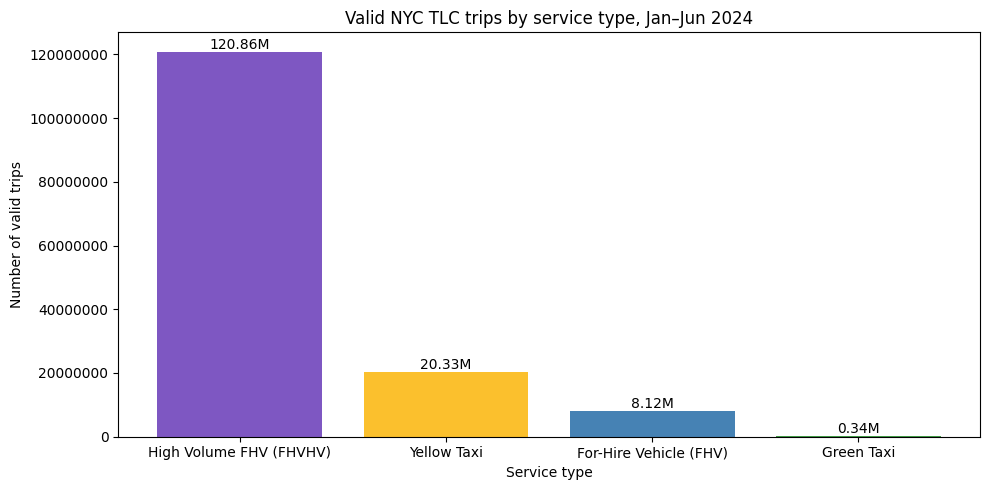

In [ ]:
colors = {
    "fhvhv": "#7E57C2",
    "yellow": "#FBC02D",
    "fhv": "#4682B4",
    "green": "#43A047",
}

plt.figure(figsize=(10, 5))
bars = plt.bar(
    summary["taxi_name"],
    summary["total_trips"],
    color=[colors[taxi_type] for taxi_type in summary["taxi_type"]],
)

plt.title("Valid NYC TLC trips by service type, Jan–Jun 2024")
plt.xlabel("Service type")
plt.ylabel("Number of valid trips")
plt.xticks(rotation=0, ha="center")
plt.ticklabel_format(style="plain", axis="y")

# ใส่จำนวนเที่ยวบนแท่งในหน่วยล้านเที่ยว
for bar, value in zip(bars, summary["total_trips"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value / 1_000_000:.2f}M",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## 14. ตรวจว่าการ Cleaning เปลี่ยนคำตอบหรือไม่

เปรียบเทียบผู้ชนะจากจำนวนแถวข้อมูลดิบกับผู้ชนะจาก Valid Trips ถ้ายังเป็นประเภทเดียวกัน ไม่ได้หมายความว่า Cleaning ไม่สำคัญ แต่หมายความว่าข้อสรุปหลักจะมีความแข็งแรงต่อเกณฑ์คุณภาพที่เราเลือก

In [ ]:
raw_summary = (
    quality_report.groupby(["taxi_type", "taxi_name"], as_index=False)["raw_rows"]
    .sum()
    .sort_values("raw_rows", ascending=False)
    .reset_index(drop=True)
)

raw_winner = raw_summary.iloc[0]

print(f"Winner before cleaning: {raw_winner['taxi_name']}")
print(f"Winner after cleaning:  {winner['taxi_name']}")
print("Same conclusion:", raw_winner["taxi_type"] == winner["taxi_type"])

Winner before cleaning: High Volume FHV (FHVHV)
Winner after cleaning:  High Volume FHV (FHVHV)
Same conclusion: True


## 15. คำตอบและการตีความ

จากตารางและกราฟจะเห็นได้ว่า **High Volume FHV (FHVHV)** เป็นบริการที่ถูกใช้มากที่สุดในครึ่งแรกของปี 2024 เมื่อวัดด้วยจำนวน Valid Trip Records

และเมื่อดูผลความต่างของ FHVHV จะมีค่าต่างจากอันดับอื่นๆ คือ Yellow Taxi, FHV และ Green Taxi ตามการเรียงลำดับผลจากมากไปน้อยอย่างมาก และถ้าตีความคู่กับผลก่อนกับหลัง Cleaning ที่ให้ผู้ชนะประเภทเดียวกัน จึงมีความมั่นใจได้ว่าปัญหาคุณภาพขนาดเล็กภายใต้เกณฑ์ที่ใช้ไม่น่าจะเปลี่ยนผู้ชนะ แต่อย่างไรก็ตาม จำนวนเที่ยวที่รายงานยังขึ้นกับความครบถ้วนของข้อมูลต้นทางด้วย

## 16. การตัดสินใจสำคัญ

### Decision 1 - ใช้จำนวน Valid Trip Records เป็น Metric

เลือกจำนวนเที่ยวแทนจำนวนผู้โดยสาร, ค่าโดยสาร หรือระยะทาง เพราะทุกชุดข้อมูลมีหนึ่งแถวต่อ Trip Record และสามารถใช้เกณฑ์เวลาเดียวกันได้ ส่วนตัวอย่าง เช่น `passenger_count` ไม่มีในทุกประเภทและมีค่าหาย จึงไม่เหมาะสำหรับการเปรียบเทียบหลัก

### Decision 2 - Query Parquet ด้วย DuckDB แล้วรวมผลระดับเดือน

ข้อมูล FHVHV มีขนาดใหญ่ การโหลดทุกคอลัมน์ของทั้ง 24 ไฟล์เข้า Pandas พร้อมกันใช้ RAM มากเกินความจำเป็น DuckDB สามารถอ่านเฉพาะคอลัมน์ที่สนใจ และเวลาที่ Query ต้องใช้ แล้วส่งกลับเพียงผลสรุปมีความเร็วมาก ทำให้เหมาะกับ Colab

### Decision 3 - ไม่ลบ Zero/Outlier โดยไม่มีหลักฐานอ้างอิง

ค่าระยะทางหรือจำนวนผู้โดยสารเป็น 0 อาจผิดปกติ แต่ไม่ได้พิสูจน์ว่าแถวนั้นไม่ใช่เที่ยวการเดินรถ และคอลัมน์ดังกล่าวก็ไม่ได้มีในทุกประเภทของบริการรถ จึงใช้เฉพาะเกณฑ์เวลาที่อธิบายได้และใช้ได้เท่าเทียมกันในทุกประเภทของบริการรถ

## 17. Traceability และความสามารถในการตรวจสอบย้อนกลับ

- URL ของทุกไฟล์ถูกสร้างจาก `taxi_type` และ `month` และแสดงไว้ใน `file_list`
- `quality_report` เก็บจำนวนแถวข้อมูลดิบ, ปัญหาที่พบ, จำนวนที่ตัดออก และ Valid Trips ของแต่ละไฟล์wไว้
- `trip_counts` เป็น Curated Output ที่เชื่อมกลับไปยังประเภทและเดือนได้
- `summary` เกิดจากการ `groupby` Curated Output โดยตรงเท่านั้น
- Validation checks ต้องผ่านทั้งหมดก่อนสรุปคำตอบของผลลัพธ์

ดังนั้นที่มาตรวจสอบผลต่อสามารถรัน Notebook จากบนลงล่าง และยังตามผลจากคำตอบย้อนกลับไปยังไฟล์ต้นทางและเกณฑ์ที่ใช้คำนวณได้

## 18. สิ่งที่เรียนรู้และข้อจำกัด

### Learning Reflection

งานนี้ทำให้ผมเห็นว่าควรกำหนด Metric ก่อนเริ่มเขียนโค้ด เพราะคำว่า “most used” สามารถตีความได้หลายแบบ และผมได้เรียนรู้ว่าไฟล์ Parquet ต่างประเภทกันก็อาจมีชื่อคอลัมน์และ Schema ไม่เหมือนกัน แม้จะมาจากแหล่งเดียวกัน การ Cleaning ควรมีเกณฑ์ และเหตุผลในการทำ ไม่ควรลบค่าที่ดูแปลกทั้งหมดโดยอัตโนมัติ และสำหรับข้อมูลขนาดใหญ่ การรวมผลสรุปที่จำเป็นก่อนจะช่วยลดการใช้หน่วยความจำได้มากครับ

### Limitations

- TLC ระบุว่าไม่รับประกันความถูกต้องหรือความครบถ้วนของข้อมูลทั้งหมด
- งานนี้ใช้ Trip Record เป็นตัวแทนหนึ่งเที่ยว แต่ไม่มีรหัส Trip ID กลางสำหรับตรวจรายการซ้ำข้ามไฟล์
- การตรวจ Valid Trip ใช้เฉพาะเวลา Pickup/Dropoff และเดือนของไฟล์ ไม่ได้ยืนยันว่าทุก Location ID ค่าโดยสาร หรือระยะทางถูกต้อง
- FHV และ FHVHV เป็น For-Hire Vehicle ไม่ใช่ Street-hail Taxi แบบ Yellow/Green จึงควรตีความคำว่า “taxi type” ว่าเป็นประเภทบริการที่ TLC เผยแพร่ในหน้า Trip Record Data
- CSV ที่สร้างถูกเก็บใน Colab runtime ซึ่งจะหายเมื่อปิด session แต่ Output สำคัญยังอยู่ใน Notebook ที่ส่ง

## 19. สรุป Workflow

Notebook นี้เริ่มจากการกำหนด Metric และขอบเขตข้อมูล ตรวจสอบ Schema และตัวอย่างข้อมูล ทำความสะอาดด้วยเกณฑ์ที่อธิบายได้ ทำชื่อคอลัมน์และผลลัพธ์ให้เป็นมาตรฐานเดียวกัน รวมข้อมูล 24 ไฟล์ ตรวจ Curated Output แล้วจึงคำนวณและนำเสนอคำตอบ กระบวนการนี้ช่วยให้ผลลัพธ์อ่านตามลำดับและตรวจสอบย้อนกลับได้ครับ